# Mushroom Classification: Edible vs. Poisonous

**Comparing K-Nearest Neighbors, Decision Tree and Naive Bayes on categorical data, with a safety-first evaluation metric.**

| | |
|---|---|
| **Dataset** | [UCI Mushroom Data Set](https://archive.ics.uci.edu/dataset/73/mushroom): 8,124 samples, 22 categorical attributes |
| **Task** | Binary classification (`edible` / `poisonous`) |
| **Primary metric** | Recall on the `poisonous` class |
| **Tie-breaker** | Accuracy |
| **Validation** | Stratified 70/30 hold-out + 5-fold stratified cross-validation |
| **Stack** | Python, pandas, scikit-learn, matplotlib |

> ⚠️ **Disclaimer:** this is a machine-learning exercise on a historical, hypothetical dataset. It must **not** be used to decide whether a real mushroom is safe to eat.

## 1. Problem framing

The two possible errors have very different costs:

| Error | Consequence |
|---|---|
| Edible predicted as poisonous (false positive) | A good mushroom is discarded. Low cost. |
| **Poisonous predicted as edible (false negative)** | **Someone eats a poisonous mushroom. Unacceptable.** |

Because of that asymmetry, models are ranked by **recall on the `poisonous` class** (the share of truly poisonous mushrooms the model catches). Accuracy is used only as a tie-breaker. Classes are nearly balanced (≈52/48), so accuracy remains a meaningful secondary signal.

## 2. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             make_scorer, recall_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

RANDOM_STATE = 42
DATA_PATH = Path("../data/agaricus-lepiota.data")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 3. Loading and decoding the data

The raw file is a **header-less CSV** where every value is a single-letter code (e.g. `p,x,s,n,t,p,...`). Column names follow the order defined in item 7 of `agaricus-lepiota.names`, and are kept in English to match the official documentation.

In [2]:
columns = [
    "class", "cap_shape", "cap_surface", "cap_color", "bruises", "odor",
    "gill_attachment", "gill_spacing", "gill_size", "gill_color",
    "stalk_shape", "stalk_root", "stalk_surface_above_ring",
    "stalk_surface_below_ring", "stalk_color_above_ring",
    "stalk_color_below_ring", "veil_type", "veil_color", "ring_number",
    "ring_type", "spore_print_color", "population", "habitat",
]

df = pd.read_csv(DATA_PATH, header=None, names=columns)
print(df.shape)
df.head(3)

(8124, 23)


,class,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,...,stalk_surface_below_ring,stalk_color_above_ring,stalk_color_below_ring,veil_type,veil_color,ring_number,ring_type,spore_print_color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m


Letters are mapped to the readable labels from the `.names` file. The same letter means different things in different columns (`n` is `none` in `odor` but `brown` in `cap_color`), so each column gets its own dictionary.

The `?` placeholder in `stalk_root` is **intentionally left out** of the mapping: `.map()` turns any unmapped code into `NaN`, which doubles as a completeness check. If a code had been missed in any dictionary, it would show up as an unexpected missing value.

In [3]:
colors = {"k": "black", "n": "brown", "b": "buff", "h": "chocolate", "c": "cinnamon",
          "g": "gray", "r": "green", "o": "orange", "p": "pink", "u": "purple",
          "e": "red", "w": "white", "y": "yellow"}
surface = {"f": "fibrous", "g": "grooves", "y": "scaly", "s": "smooth", "k": "silky"}

value_maps = {
    "class": {"e": "edible", "p": "poisonous"},
    "cap_shape": {"b": "bell", "c": "conical", "x": "convex", "f": "flat", "k": "knobbed", "s": "sunken"},
    "cap_surface": surface,
    "cap_color": colors,
    "bruises": {"t": "bruises", "f": "no"},
    "odor": {"a": "almond", "l": "anise", "c": "creosote", "y": "fishy", "f": "foul",
             "m": "musty", "n": "none", "p": "pungent", "s": "spicy"},
    "gill_attachment": {"a": "attached", "d": "descending", "f": "free", "n": "notched"},
    "gill_spacing": {"c": "close", "w": "crowded", "d": "distant"},
    "gill_size": {"b": "broad", "n": "narrow"},
    "gill_color": colors,
    "stalk_shape": {"e": "enlarging", "t": "tapering"},
    "stalk_root": {"b": "bulbous", "c": "club", "u": "cup", "e": "equal", "z": "rhizomorphs", "r": "rooted"},
    "stalk_surface_above_ring": surface,
    "stalk_surface_below_ring": surface,
    "stalk_color_above_ring": colors,
    "stalk_color_below_ring": colors,
    "veil_type": {"p": "partial", "u": "universal"},
    "veil_color": colors,
    "ring_number": {"n": "none", "o": "one", "t": "two"},
    "ring_type": {"c": "cobwebby", "e": "evanescent", "f": "flaring", "l": "large",
                  "n": "none", "p": "pendant", "s": "sheathing", "z": "zone"},
    "spore_print_color": colors,
    "population": {"a": "abundant", "c": "clustered", "n": "numerous",
                   "s": "scattered", "v": "several", "y": "solitary"},
    "habitat": {"g": "grasses", "l": "leaves", "m": "meadows", "p": "paths",
                "u": "urban", "w": "waste", "d": "woods"},
}

for column, mapping in value_maps.items():
    df[column] = df[column].map(mapping)

df.head(3)

,class,cap_shape,cap_surface,cap_color,bruises,odor,gill_attachment,gill_spacing,gill_size,gill_color,...,stalk_surface_below_ring,stalk_color_above_ring,stalk_color_below_ring,veil_type,veil_color,ring_number,ring_type,spore_print_color,population,habitat
0,poisonous,convex,smooth,brown,bruises,pungent,free,close,narrow,black,...,smooth,white,white,partial,white,one,pendant,black,scattered,urban
1,edible,convex,smooth,yellow,bruises,almond,free,close,broad,black,...,smooth,white,white,partial,white,one,pendant,brown,numerous,grasses
2,edible,bell,smooth,white,bruises,anise,free,close,broad,brown,...,smooth,white,white,partial,white,one,pendant,brown,numerous,meadows


## 4. Data quality checks

In [4]:
missing = df.isna().sum()
missing[missing > 0]

stalk_root    2480
dtype: int64

Only `stalk_root` has missing values: **2,480 (≈30.5%)**, exactly the count stated in the dataset documentation. This confirms that every other code was decoded correctly.

In [5]:
# How are the missing values distributed across classes?
df.loc[df["stalk_root"].isna(), "class"].value_counts()

class
poisonous    1760
edible        720
Name: count, dtype: int64

In [6]:
df.nunique().sort_values().head(4)

veil_type          1
class              2
gill_attachment    2
gill_spacing       2
dtype: int64

In [7]:
print("Duplicated rows:", df.duplicated().sum())
df["class"].value_counts(normalize=True).round(3)

Duplicated rows: 0


class
edible       0.518
poisonous    0.482
Name: proportion, dtype: float64

**Findings**
- `veil_type` holds a single value (`partial`) for every row, so it carries no information.
- No duplicated rows.
- Classes are balanced (≈51.8% edible / 48.2% poisonous).
- Missing `stalk_root` values are concentrated in poisonous mushrooms (1,760 vs. 720). This is relevant for the limitations section.

## 5. Cleaning decisions

| Decision | Rationale |
|---|---|
| Drop `stalk_root` | ≈30% missing. Dropping the column keeps all 8,124 samples, whereas dropping rows would discard almost a third of the data. |
| Drop `veil_type` | Constant feature (one unique value), so it has zero discriminative power. |

In [8]:
df = df.drop(columns=["stalk_root", "veil_type"])
assert df.isna().sum().sum() == 0
df.shape

(8124, 21)

## 6. Train/test split

| Choice | Value | Rationale |
|---|---|---|
| Proportion | 70% train / 30% test | ≈2,400 test samples give a reliable estimate while leaving plenty of data to learn from. |
| Stratification | Yes | Keeps the ≈52/48 class ratio identical in both sets. |
| `random_state` | 42 | Reproducible split. |

In [9]:
X = df.drop(columns=["class"])
y = df["class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
pd.DataFrame({"train": y_train.value_counts(normalize=True).round(3),
              "test": y_test.value_counts(normalize=True).round(3)})

Train: (5686, 20) | Test: (2438, 20)


,train,test
class,,
edible,0.518,0.518
poisonous,0.482,0.482


## 7. Encoding strategy

All features are nominal, so the encoding must match each algorithm:

| Model | Encoding | Why |
|---|---|---|
| KNN | One-Hot | KNN relies on distances. Ordinal codes would invent a false order between categories. With one-hot, distance ≈ number of differing attributes. |
| Decision Tree | One-Hot | Produces human-readable splits (e.g. `odor_none`). |
| Naive Bayes | Ordinal | `CategoricalNB` treats integers as category labels and models per-category frequencies directly. |

Encoders are **fit on the training set only** and then applied to the test set, to avoid data leakage.

In [10]:
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_train_ohe = ohe.fit_transform(X_train)
X_test_ohe = ohe.transform(X_test)

ord_enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X_train_ord = ord_enc.fit_transform(X_train).astype(int)
X_test_ord = ord_enc.transform(X_test).astype(int)

print("One-hot features:", X_train_ohe.shape[1], "| Ordinal features:", X_train_ord.shape[1])

One-hot features: 111 | Ordinal features: 20


A small helper keeps the evaluation identical across models:

In [11]:
LABELS = ["edible", "poisonous"]
results = {}

def evaluate(name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=LABELS)
    results[name] = {
        "recall_poisonous": recall_score(y_true, y_pred, pos_label="poisonous"),
        "accuracy": accuracy_score(y_true, y_pred),
        "poisonous_missed": int(cm[1, 0]),
        "edible_discarded": int(cm[0, 1]),
    }
    print(f"=== {name} ===")
    print(pd.DataFrame(cm, index=[f"true {l}" for l in LABELS],
                       columns=[f"pred {l}" for l in LABELS]))
    print()
    print(classification_report(y_true, y_pred, labels=LABELS, digits=4))

## 8. Models

### 8.1 K-Nearest Neighbors

**Choice:** `k = 5`, the scikit-learn default, used as a deliberate starting point with no hyperparameter tuning. An odd `k` avoids ties in a two-class vote.

In [12]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_ohe, y_train)
evaluate("KNN (k=5)", y_test, knn.predict(X_test_ohe))

=== KNN (k=5) ===
                pred edible  pred poisonous
true edible            1263               0
true poisonous            0            1175

              precision    recall  f1-score   support

      edible     1.0000    1.0000    1.0000      1263
   poisonous     1.0000    1.0000    1.0000      1175

    accuracy                         1.0000      2438
   macro avg     1.0000    1.0000    1.0000      2438
weighted avg     1.0000    1.0000    1.0000      2438



### 8.2 Decision Tree

**Choice:** `max_depth = 4`, deliberately limited to keep the model **interpretable** (small enough to read and explain). The depth was fixed before looking at test results, and was **not** changed afterwards, to keep the test set unbiased.

In [13]:
tree = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
tree.fit(X_train_ohe, y_train)
evaluate("Decision Tree (depth=4)", y_test, tree.predict(X_test_ohe))

=== Decision Tree (depth=4) ===
                pred edible  pred poisonous
true edible            1263               0
true poisonous            3            1172

              precision    recall  f1-score   support

      edible     0.9976    1.0000    0.9988      1263
   poisonous     1.0000    0.9974    0.9987      1175

    accuracy                         0.9988      2438
   macro avg     0.9988    0.9987    0.9988      2438
weighted avg     0.9988    0.9988    0.9988      2438



In [14]:
print(export_text(tree, feature_names=list(ohe.get_feature_names_out())))

|--- odor_none <= 0.50
|   |--- bruises_bruises <= 0.50
|   |   |--- class: poisonous
|   |--- bruises_bruises >  0.50
|   |   |--- spore_print_color_chocolate <= 0.50
|   |   |   |--- odor_pungent <= 0.50
|   |   |   |   |--- class: edible
|   |   |   |--- odor_pungent >  0.50
|   |   |   |   |--- class: poisonous
|   |   |--- spore_print_color_chocolate >  0.50
|   |   |   |--- class: poisonous
|--- odor_none >  0.50
|   |--- spore_print_color_green <= 0.50
|   |   |--- stalk_surface_below_ring_scaly <= 0.50
|   |   |   |--- cap_surface_grooves <= 0.50
|   |   |   |   |--- class: edible
|   |   |   |--- cap_surface_grooves >  0.50
|   |   |   |   |--- class: poisonous
|   |   |--- stalk_surface_below_ring_scaly >  0.50
|   |   |   |--- ring_number_two <= 0.50
|   |   |   |   |--- class: poisonous
|   |   |   |--- ring_number_two >  0.50
|   |   |   |   |--- class: edible
|   |--- spore_print_color_green >  0.50
|   |   |--- class: poisonous



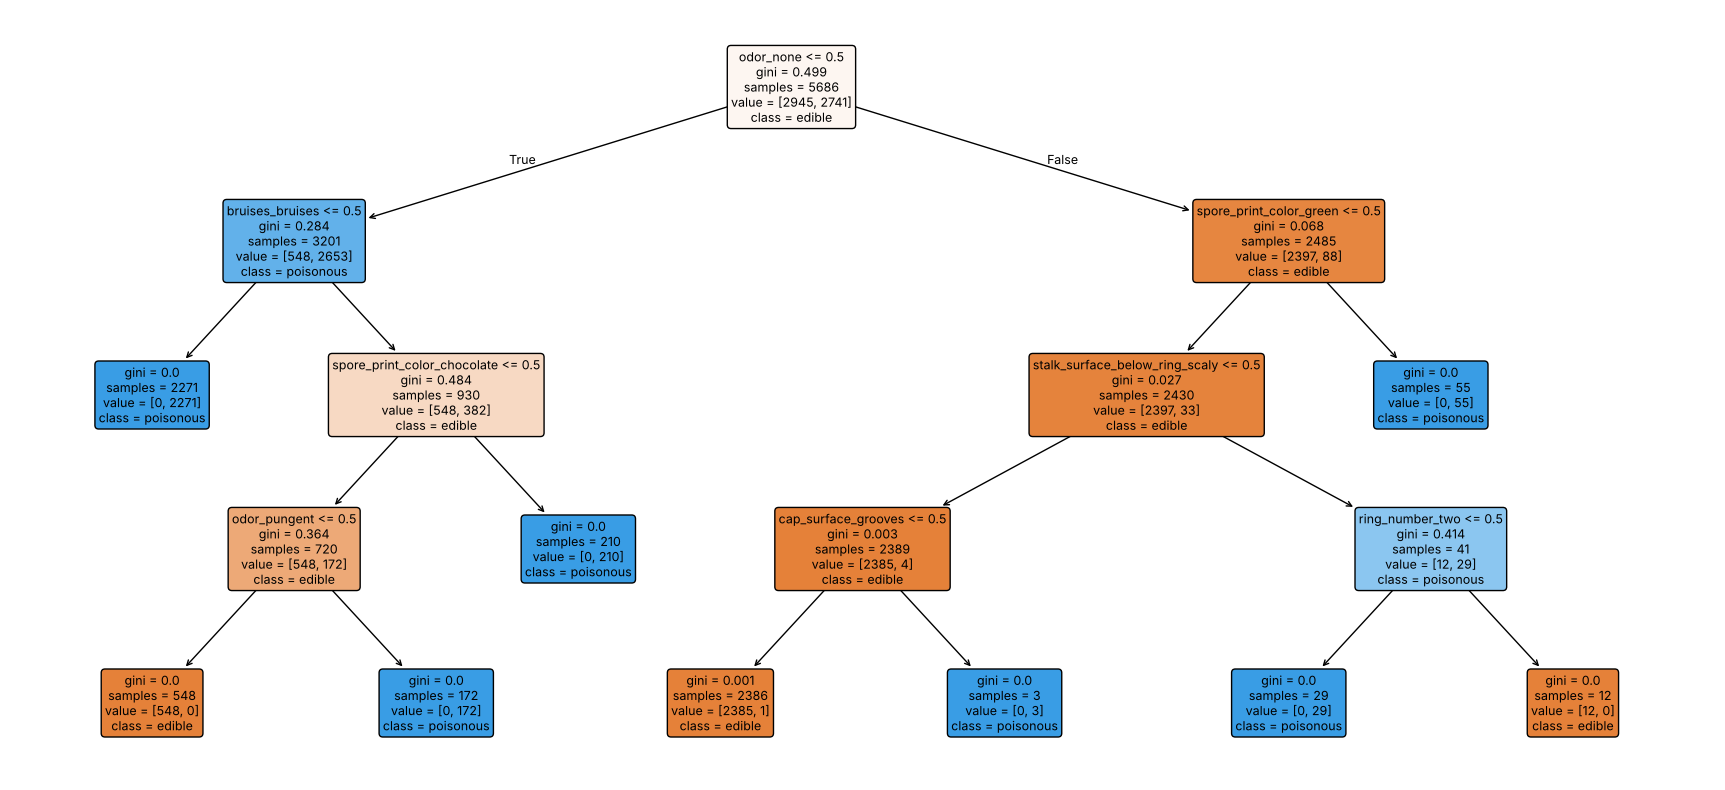

In [15]:
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(tree, feature_names=ohe.get_feature_names_out(), class_names=tree.classes_,
          filled=True, rounded=True, fontsize=9, ax=ax)
fig.savefig(FIG_DIR / "decision_tree.png", dpi=120, bbox_inches="tight")
plt.show()

**Reading the tree.** The root split is **`odor`**, which the model found on its own. It matches the simplest published rule for this dataset ("odor is not almond, anise or none → poisonous", ≈98.5% accuracy; see item 3 of the `.names` file). Spore print color, bruising and stalk surface refine the remaining cases.

**Trade-off.** At depth 4, the tree lets **3 poisonous mushrooms through**. This is the explicit cost of choosing interpretability over the last fraction of recall.

### 8.3 Naive Bayes

**Choice:** `CategoricalNB` with `alpha = 1.0` (standard Laplace smoothing), which prevents a category unseen in one class from zeroing out the whole probability product.

In [16]:
n_categories = [len(c) for c in ord_enc.categories_]

nb = CategoricalNB(alpha=1.0, min_categories=n_categories)
nb.fit(X_train_ord, y_train)
evaluate("Naive Bayes (alpha=1)", y_test, nb.predict(X_test_ord))

=== Naive Bayes (alpha=1) ===
                pred edible  pred poisonous
true edible            1255               8
true poisonous           90            1085

              precision    recall  f1-score   support

      edible     0.9331    0.9937    0.9624      1263
   poisonous     0.9927    0.9234    0.9568      1175

    accuracy                         0.9598      2438
   macro avg     0.9629    0.9585    0.9596      2438
weighted avg     0.9618    0.9598    0.9597      2438



**Why Naive Bayes underperforms.** It assumes features are conditionally independent given the class. Here they are strongly correlated: the dataset describes 23 species, each with a characteristic *combination* of odor, spore color, stalk surface and so on. Naive Bayes counts the same underlying evidence several times and becomes over-confident on borderline cases. KNN and the tree, by contrast, exploit feature *combinations* directly.

## 9. Hold-out comparison

In [17]:
holdout = (pd.DataFrame(results).T
           .sort_values(["recall_poisonous", "accuracy"], ascending=False))
holdout.style.format({"recall_poisonous": "{:.2%}", "accuracy": "{:.2%}"})

,recall_poisonous,accuracy,poisonous_missed,edible_discarded
KNN (k=5),100.00%,100.00%,0.000000,0.000000
Decision Tree (depth=4),99.74%,99.88%,3.000000,0.000000
Naive Bayes (alpha=1),92.34%,95.98%,90.000000,8.000000


## 10. Cross-validation

A single 70/30 split could be lucky. To check robustness, each model is re-evaluated with **5-fold stratified cross-validation** on the full dataset.

Encoder and model are wrapped in a **`Pipeline`**, so the encoder is re-fit on the training folds of every iteration and never sees the validation fold (no leakage). Hyperparameters are exactly the ones chosen above.

In [18]:
n_categories_full = [X[c].nunique() for c in X.columns]

pipelines = {
    "KNN (k=5)": make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree (depth=4)": make_pipeline(
        OneHotEncoder(handle_unknown="ignore"),
        DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)),
    "Naive Bayes (alpha=1)": make_pipeline(
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
        CategoricalNB(alpha=1.0, min_categories=n_categories_full)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"recall_poisonous": make_scorer(recall_score, pos_label="poisonous"),
           "accuracy": "accuracy"}

cv_rows = {}
for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    cv_rows[name] = {
        "recall_poisonous_mean": scores["test_recall_poisonous"].mean(),
        "recall_poisonous_std": scores["test_recall_poisonous"].std(),
        "accuracy_mean": scores["test_accuracy"].mean(),
        "accuracy_std": scores["test_accuracy"].std(),
        "recall_per_fold": [round(s, 4) for s in scores["test_recall_poisonous"]],
    }

cv_results = pd.DataFrame(cv_rows).T
cv_results

,recall_poisonous_mean,recall_poisonous_std,accuracy_mean,accuracy_std,recall_per_fold
KNN (k=5),1.0,0.0,1.0,0.0,"[1.0, 1.0, 1.0, 1.0, 1.0]"
Decision Tree (depth=4),0.998978,0.000956,0.999508,0.000461,"[1.0, 0.9987, 1.0, 0.9974, 0.9987]"
Naive Bayes (alpha=1),0.924926,0.013139,0.960857,0.005777,"[0.9133, 0.9374, 0.9374, 0.9055, 0.931]"


**Interpretation**
- The ranking from the hold-out split is **confirmed in every fold**.
- **KNN** scores 100% recall and accuracy in all 5 folds, with zero variance.
- **Decision Tree** is consistent but pays a small, recurring price for its depth limit.
- **Naive Bayes** is both the weakest and the least stable model, which is consistent with its independence assumption being violated.

## 11. Conclusion

| Rank | Model | Hold-out recall (poisonous) | CV recall (mean ± std) | Strength |
|---|---|---|---|---|
| 🥇 | **KNN (k=5)** | **100.00%** | **100.00% ± 0.00** | Best safety metric, perfectly stable |
| 🥈 | Decision Tree (depth=4) | 99.74% | 99.90% ± 0.10 | Fully interpretable rules |
| 🥉 | Naive Bayes (α=1) | 92.34% | 92.49% ± 1.31 | Simple and fast, but independence assumption fails |

**KNN is the recommended model** under the safety-first criterion. If explainability were a hard requirement (for example, to give a field guide a set of rules), the decision tree would be the pragmatic alternative, with its residual risk stated explicitly.

## 12. Limitations and next steps

- **Near-separable data.** Perfect scores reflect a dataset that is known to be almost deterministic. They do not reflect how a model would perform on real-world field observations.
- **Hypothetical samples.** Records were generated from field-guide descriptions of 23 species, not from measured specimens. "Unknown edibility" species were merged into the poisonous class.
- **Dropped signal.** Missing `stalk_root` values are concentrated in poisonous samples. Encoding the gap as an explicit `missing` category could recover that information.
- **No hyperparameter tuning.** `k`, `max_depth` and `alpha` were set by reasoning, not tuned. A nested cross-validation grid search is the natural next step, especially for tree depth.
- **Single metric focus.** A cost-sensitive threshold analysis (e.g. on predicted probabilities) would make the safety trade-off explicit for deployment.